# Cross-section of humidity, temperature and 3-D wind in height

A vertical cross-section shows how a quantity changes with height along a line over the Earth's surface. In this tutorial we plot the relative humidity, the equivalent potential temperature and the 3-D wind along a line from (37.1°N, 104.4°W) to (37.3°N, 89.5°W), in height above sea level, and show the ground in charcoal. The data is on model levels, which we interpolate to height levels.

This feature is **experimental**. For a more detailed version of this example, see [the high-level notebook](../high/cross_section_wind3d_height_ml_orog.ipynb).

## Imports

First we import the tools we need.

In [1]:
import sys

import earthkit.data as ekd
import earthkit.plots as ekp
import numpy as np
from earthkit.geo.polyline import sample_polyline
from earthkit.meteo import thermo, wind

sys.path.insert(0, "..")  # xsection.py is in docs/experimental
from xsection import (
    cross_section,
    hybrid_coefficients,
    model_to_height,
    pressure_on_model_levels,
    surface_pressure,
    wind_components,
)

## Get the data

We load a small sample file with forecast data on model levels. We pick the temperature (`t`), the specific humidity (`q`), the wind components (`u` and `v`), the vertical velocity (`w`, given as the pressure velocity omega) and the logarithm of the surface pressure (`lnsp`). The surface geopotential (`z`) is from a different time step, so we pick it separately. We also read the coefficients that describe the model levels.

In [2]:
ds = ekd.from_source("sample", "xs_ml_wind_orog.grib").to_fieldlist()

fl = ds.sel({"parameter.variable": ["t", "q", "u", "v", "w", "lnsp"]})
fl_z = ds.sel({"parameter.variable": "z"})
A, B = hybrid_coefficients(fl)

xs_ml_wind_orog.grib:   0%|          | 0.00/3.59M [00:00<?, ?B/s]

## Define the line

We choose 200 evenly spaced points along a straight line in latitude and longitude, from (37.1°N, 104.4°W) to (37.3°N, 89.5°W).

In [3]:
lats, lons = sample_polyline([37.1, 37.3], [-104.4, -89.5], n=200, method="linear")

## Compute the cross-section

Now we compute the values of the data at the points of the line, and the surface geopotential separately. We rename the pressure velocity `w` to `omega`, because we compute the vertical velocity in m/s from it below. Log messages may appear while this runs; you can ignore them.

In [4]:
xs = cross_section(fl, lats, lons).rename(w="omega")
zs = cross_section(fl_z, lats, lons)["z"]

ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridSubtype=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridSubtype:
	C
	F
	N
	T
	U
	V
	W
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR 

Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridSubtype=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridSubtype:
	C
	F
	N
	T
	U
	V
	W
	undefined
	unknown
ECCODES ERROR   :  concept: no match for unstructuredGridType=
ECCODES ERROR   :  concept: input handle edition=2, centre=ecmf
ECCODES ERROR   :  concept: input handle tablesVersion=28
Here are some possible values for concept unstructuredGridType:
	CORE2
	DART
	NG5
	ORCA025
	ORCA1
	ORCA12
	ORCA2
	eORCA025
	eORCA1
	eORCA12
	undefined
	unknown
ECCODES ERROR 

Problem with calculation of geographic attributes
Traceback (most recent call last):
  File "/Users/cgr/git/earthkit-data/src/earthkit/data/utils/message.py", line 299, in set
    return eccodes.codes_set(self._handle, name, value)
           ~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 2163, in grib_set
    grib_set_string(msgid, key, value)
    ~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 523, in grib_set_string
    GRIB_CHECK(lib.grib_set_string(h, key.encode(ENC), bvalue, length_p))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/gribapi.py", line 232, in GRIB_CHECK
    errors.raise_grib_error(errid)
    ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/Users/cgr/venv/dev/lib/python3.13/site-packages/gribapi/errors.py", line 386, in raise_grib_error

## Compute the vertical velocity, relative humidity and equivalent potential temperature

We compute the surface pressure and the pressure on the model levels, and from them the vertical velocity in m/s, the relative humidity and the equivalent potential temperature.

In [5]:
sp = surface_pressure(xs)
p = pressure_on_model_levels(xs, A, B, sp)

w = wind.w_from_omega(xs["omega"], xs["t"], p)
xs["w"] = w.assign_attrs(standard_name="upward_air_velocity", long_name="Vertical velocity", units="m s-1")

rh = thermo.relative_humidity_from_specific_humidity(xs["t"], xs["q"], p)
xs["rh"] = rh.assign_attrs(standard_name="relative_humidity", long_name="Relative humidity", units="%")

ept = thermo.ept_from_specific_humidity(xs["t"], xs["q"], p)
xs["ept"] = ept.assign_attrs(
    standard_name="air_equivalent_potential_temperature", long_name="Equivalent potential temperature", units="K"
)

## Compute the wind along the line

We compute the wind component along the line (positive in the direction of travel, here eastwards) from `u` and `v`. It is added to the data as `wp`.

In [6]:
xs = wind_components(xs, method="linear")

## Interpolate to height levels

The model levels follow the ground, so we interpolate the variables to fixed heights above sea level, from 0 to 10000 m every 100 m. The orography is added to the result.

In [7]:
target_h = np.arange(0, 10001, 100)
xs_h = model_to_height(xs, A, B, sp, zs, target_h, names=["rh", "ept", "wp", "w"])
xs_h

<xarray.Dataset> Size: 654kB
Dimensions:                  (height: 101, distance: 200)
Coordinates:
  * height                   (height) int64 808B 0 100 200 ... 9800 9900 10000
  * distance                 (distance) float64 2kB 0.0 6.642 ... 1.32e+03
    latitude                 (distance) float64 2kB 37.1 37.1 37.1 ... 37.3 37.3
    longitude                (distance) float64 2kB -104.4 -104.3 ... -89.5
    forecast_reference_time  datetime64[ns] 8B 2022-04-29T12:00:00
    step                     timedelta64[ns] 8B 12:00:00
    valid_time               datetime64[ns] 8B 2022-04-30
Data variables:
    rh                       (height, distance) float64 162kB nan nan ... 43.53
    ept                      (height, distance) float64 162kB nan nan ... 328.4
    wp                       (height, distance) float64 162kB nan nan ... 7.819
    w                        (height, distance) float64 162kB nan ... 0.01067
    orography                (distance) float64 2kB 2.018e+03 ... 136.6
Attributes:
    Conventions:  CF-1.8
    institution:  ECMWF

## Plot the cross-section

We draw the relative humidity as green shading, the equivalent potential temperature as brown contour lines, and the wind as arrows, whose vertical part is the vertical velocity multiplied by 100 so that it is visible. The orography is the charcoal area at the bottom. Then we label the axes.

['37.11°N/104°W', '37.13°N/102°W', '37.16°N/100°W', '37.19°N/98°W', '37.21°N/96°W', '37.24°N/94°W', '37.27°N/92°W', '37.29°N/90°W']


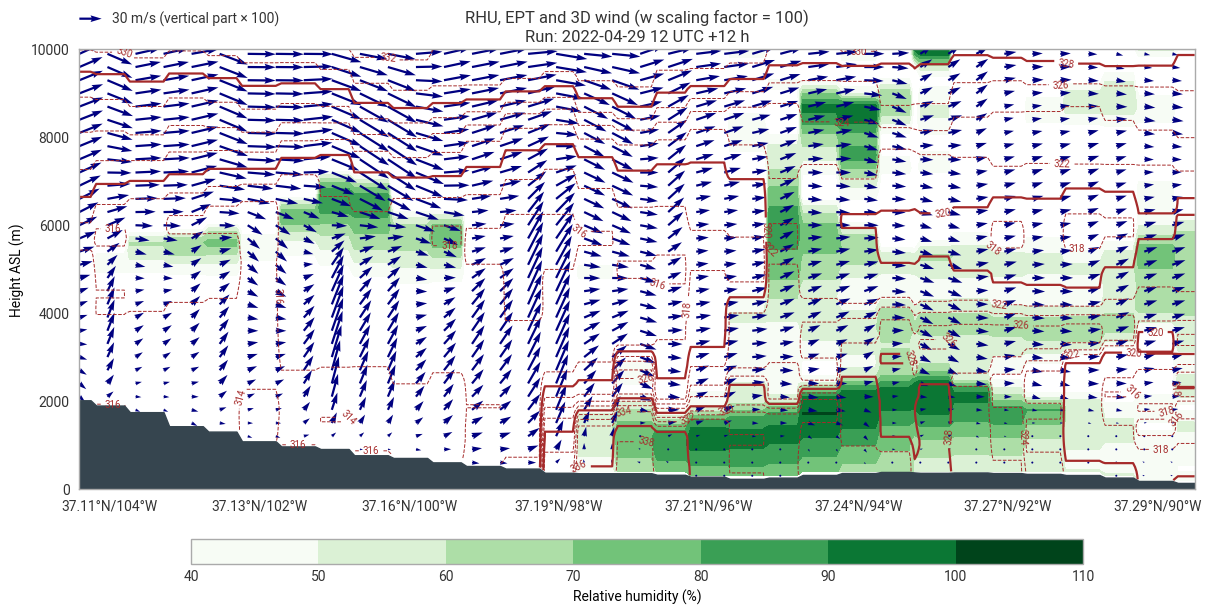

In [8]:
rh_levels = list(range(40, 111, 10))
ept_min, ept_max = np.nanmin(xs_h["ept"].values), np.nanmax(xs_h["ept"].values)
ept_levels = list(range(int(np.floor(ept_min / 2) * 2), int(np.ceil(ept_max / 2) * 2) + 1, 2))
ept_dashed = [lev for lev in ept_levels if lev % 8 != 0]
ept_solid = [lev for lev in ept_levels if lev % 8 == 0]

lats, lons, distance = xs_h["latitude"].values, xs_h["longitude"].values, xs_h["distance"].values

chart = ekp.Subplot(figsize=(12, 6))

# relative humidity: green shading
chart.contourf(
    xs_h["rh"],
    x="distance",
    y="height",
    style=ekp.styles.Style(levels=rh_levels, colors="Greens", ticks=rh_levels),
    resample=False,
)
chart.figure.legend(label="Relative humidity (%)")

# equivalent potential temperature: dashed lines every 2 K, solid labelled lines every 8 K
chart.contour(
    xs_h["ept"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(levels=ept_dashed, colors="brown", linewidths=0.7, linestyles="dashed", legend_style=None),
    resample=False,
)
chart.contour(
    xs_h["ept"],
    x="distance",
    y="height",
    style=ekp.styles.Contour(
        levels=ept_solid,
        colors="brown",
        linewidths=1.6,
        labels=True,
        label_kwargs={"label_fmt": "%d"},
        legend_style=None,
    ),
    resample=False,
)

# 3-D wind: along-line wind and 100 * vertical velocity, every 3rd level and every 5th point
rows, cols = slice(None, None, 3), slice(None, None, 5)
X, Y = np.meshgrid(distance[cols], xs_h["height"].values[rows])
U_arrow = xs_h["wp"].values[rows, cols]  # m/s, along the line (eastwards)
V_arrow = 100 * xs_h["w"].values[rows, cols]  # m/s, vertical velocity times 100, up

ax = chart.ax
arrows = ax.quiver(X, Y, U_arrow, V_arrow, color="navy", angles="uv", scale=1500, width=0.002)
ax.quiverkey(arrows, 0.02, 1.07, 30, "30 m/s (vertical part × 100)", coordinates="axes", labelpos="E")

# orography: charcoal polygon from the surface height down to 0 m, drawn on top
chart.fill_between(xs_h["orography"], 0, x=xs_h["distance"], color="#36454f", alpha=1)

# 8 ticks where the line crosses the longitudes 104W ... 90W (lons increase along the line)
tick_lons = np.arange(-104, -89, 2)
tick_distance = np.interp(tick_lons, lons, distance)
tick_lats = np.interp(tick_lons, lons, lats)
tick_labels = [f"{round(lat, 2):g}°N/{abs(lon)}°W" for lat, lon in zip(tick_lats, tick_lons)]
print(tick_labels)

ax.set_xlim(distance[0], distance[-1])
ax.set_ylim(0, 10000)
ax.set_xticks(tick_distance)
ax.set_xticklabels(tick_labels)
ax.grid(False)  # no grid lines over the arrows, as in Metview
ax.set_ylabel("Height ASL (m)")
ax.set_title("RHU, EPT and 3D wind (w scaling factor = 100)\nRun: 2022-04-29 12 UTC +12 h")

chart.show()